# Databases - Laboratory

This tutorial covers `LabDB`, the database for water samples analysed in a laboratory. Data follows a chain:

1. **sites**: places where field work happens, as points;
2. **samples**: bottles collected at a site, at a sampling time;
3. **mixtures**: what the lab actually analyses, usually one sample alone, sometimes a blend of several;
4. **records**: one result per mixture and parameter, at an analysis time.

The example is a river monitoring program with four sampling points and four campaigns, analysed for turbidity, pH and sodium.

```{seealso}
Check out the {doc}`Databases - Spatial <databases_03_spatial>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.databases import LabDB

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/databases")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\databases


## Sites and catalogs

Four sampling points run from upstream (`P1`) to downstream (`P4`), below a town:

In [2]:
sites = gpd.GeoDataFrame(
    data={"name": ["P1", "P2", "P3", "P4"]},
    geometry=gpd.points_from_xy(x=[-51.30, -51.22, -51.15, -51.08], y=[-29.90, -29.95, -30.02, -30.05]),
    crs="EPSG:4674",
)
file_sites = OUTPUT_DIR / "lab_sites.gpkg"
sites.to_file(filename=file_sites, driver="GPKG")

The specs point to the variables `turbidity`, `ph` and `sodium (physical-chemistry)`, all with the `instant` statistic, since each result is a single analysis, not an aggregate. The sources catalog that ships with `plans` has no laboratory, so the setup points to a custom one. Any catalog can be replaced this way:

In [3]:
file_sources = OUTPUT_DIR / "lab_sources.csv"
pd.DataFrame(
    [{"name": "River Survey", "alias": "RS", "title": "River monitoring program", "abstract": "Synthetic campaigns", "citation": None, "url": None}]
).to_csv(file_sources, sep=";", index=False)


def make_spec(name, variable, abstract):
    # one spec of lab results
    return {
        "name": name,
        "abstract": abstract,
        "method": "laboratory analysis",
        "timestep": "event",
        "extent": "sample",
        "scale": 1,
        "offset": 0,
        "start": "2024-01-01",
        "end": None,
        "variable_name": variable,
        "statistic_name": "instant",
        "source_name": "River Survey",
    }


specs = [
    make_spec("TURB_LAB", "turbidity", "Turbidity by nephelometry"),
    make_spec("PH_LAB", "ph", "pH by electrode, in triplicate"),
    make_spec("NA_LAB", "sodium (physical-chemistry)", "Dissolved sodium by ion chromatography"),
]
file_specs = OUTPUT_DIR / "lab_specs.json"
file_specs.write_text(json.dumps(specs, indent=2), encoding="utf-8")

db = LabDB(name="River Lab")
db.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "lab_db.gpkg")},
        "specs": {"path": str(file_specs)},
        "spatial": {"file": str(file_sites)},
        "catalogs": {"sources": str(file_sources)},
    },
    overwrite=True,
)
db.query_sql(sql="SELECT name, units, domain FROM variables WHERE name IN ('turbidity', 'ph', 'sodium (physical-chemistry)')")

,name,units,domain
0,ph,-,[0U14]
1,sodium (physical-chemistry),mg/L,[0U)
2,turbidity,NTU,[0U)


## Samples

Each campaign collects one bottle per site, in the morning, moving downstream. The field sheet of the third campaign lost the time of `P2`; following a common convention, it is set to noon:

In [4]:
campaigns = {"C1": "2024-02-10", "C2": "2024-05-12", "C3": "2024-08-14", "C4": "2024-11-09"}
rows = []
for campaign, day in campaigns.items():
    for k, site in enumerate(sites["name"]):
        time = "12:00" if (campaign, site) == ("C3", "P2") else f"{8 + k}:30"
        rows.append({"name": f"{campaign}-{site}", "site_name": site, "datetime": f"{day} {time}"})
samples = pd.DataFrame(rows)
db.insert_samples(dataframe=samples)
db.query_sql(sql="SELECT id, name, datetime(datetime, 'unixepoch') AS datetime, site_id FROM samples LIMIT 5")

,id,name,datetime,site_id
0,1,C1-P1,2024-02-10 08:30:00,1
1,2,C1-P2,2024-02-10 09:30:00,2
2,3,C1-P3,2024-02-10 10:30:00,3
3,4,C1-P4,2024-02-10 11:30:00,4
4,5,C2-P1,2024-05-12 08:30:00,1


## Mixtures

Usually the lab analyses each bottle alone. Without a `name` column, `.insert_mixtures()` makes one mixture per sample, named after it. In the last campaign, the bottles of `P3` and `P4` were half empty, so the lab blended them into one mixture. A blend takes one row per sample, with the same mixture name:

In [5]:
single = samples.loc[~samples["name"].isin(["C4-P3", "C4-P4"]), ["name"]]
db.insert_mixtures(dataframe=single.rename(columns={"name": "sample_name"}))
db.insert_mixtures(dataframe=pd.DataFrame({"name": "C4-P34", "sample_name": ["C4-P3", "C4-P4"]}))
db.query_sql(
    sql="SELECT m.name AS mixture, s.name AS sample FROM mixtures m "
    "JOIN mixture_samples ms ON ms.mixture_id = m.id JOIN samples s ON s.id = ms.sample_id "
    "WHERE m.name LIKE 'C4%'"
)

,mixture,sample
0,C4-P1,C4-P1
1,C4-P2,C4-P2
2,C4-P34,C4-P3
3,C4-P34,C4-P4


## Results

Lab results usually arrive as one large table. Here, the town raises turbidity and sodium downstream, and pH drops a little. pH is measured three times per mixture. The analyses happen a few days after sampling, but the dates of the third campaign were not recorded:

In [6]:
rng = np.random.default_rng(seed=11)  # ensure reproducibility
mixtures = db.query_sql(sql="SELECT id, name FROM mixtures")
results = []
for mixture in mixtures["name"]:
    campaign = mixture[:2]
    position = int(mixture[-1]) - 1  # 0 upstream to 3 downstream
    wet = campaign in ("C2", "C3")
    analysis = None if campaign == "C3" else pd.Timestamp(campaigns[campaign]) + pd.Timedelta(days=int(rng.integers(2, 6)))
    turbidity = (8 + 10 * position) * (1.8 if wet else 1) * rng.lognormal(sigma=0.2)
    sodium = 0.2 + 3 * position + rng.normal(scale=0.3)
    results.append({"mixture_name": mixture, "parameter": "TURB_LAB", "value": turbidity, "datetime": analysis})
    results.append({"mixture_name": mixture, "parameter": "NA_LAB", "value": sodium, "datetime": analysis})
    for _ in range(3):
        ph = 7.4 - 0.25 * position + rng.normal(scale=0.05)
        results.append({"mixture_name": mixture, "parameter": "PH_LAB", "value": round(ph, 2), "datetime": analysis})
results = pd.DataFrame(results)
results.head(6)

,mixture_name,parameter,value,datetime
0,C1-P1,TURB_LAB,10.500166,2024-02-12
1,C1-P1,NA_LAB,0.567416,2024-02-12
2,C1-P1,PH_LAB,7.370000,2024-02-12
3,C1-P1,PH_LAB,7.390000,2024-02-12
4,C1-P1,PH_LAB,7.370000,2024-02-12
5,C1-P2,TURB_LAB,20.172434,2024-02-12


Sodium has a detection limit of 0.5 mg/L. Results below it are *not detected*: they get the `nondetect` flag (`-3`) and keep the limit as their value. All other results are `regular` (`1`). With mixed flags, the flag goes in a `flag_value` column instead of the `flag` argument:

In [7]:
lod = 0.5
results["flag_value"] = 1
below = (results["parameter"] == "NA_LAB") & (results["value"] < lod)
results.loc[below, ["value", "flag_value"]] = [lod, -3]
print(f"{below.sum()} sodium results not detected")

for spec_name, group in results.groupby("parameter"):
    db.insert_records(dataframe=group.drop(columns="parameter"), spec_name=spec_name)

3 sodium results not detected


## Querying

Records point to mixtures, and queries reach the sites through the chain. Rows come ordered by the sampling time, the time the water was in the river. The `sample_datetime` column holds it, next to the analysis `datetime`, which is empty when unknown:

In [8]:
df = db.query_records(query_dict={"spec_name": "TURB_LAB"})
df[["sample_datetime", "datetime", "value", "mixture_id"]]

,sample_datetime,datetime,value,mixture_id
0,2024-02-10 08:30:00+00:00,2024-02-12 00:00:00+00:00,10.500166,1
1,2024-02-10 09:30:00+00:00,2024-02-12 00:00:00+00:00,20.172434,2
2,2024-02-10 10:30:00+00:00,2024-02-12 00:00:00+00:00,32.081521,3
3,2024-02-10 11:30:00+00:00,2024-02-14 00:00:00+00:00,36.491530,4
4,2024-05-12 08:30:00+00:00,2024-05-15 00:00:00+00:00,12.592672,5
5,2024-05-12 09:30:00+00:00,2024-05-16 00:00:00+00:00,24.038715,6
6,2024-05-12 10:30:00+00:00,2024-05-17 00:00:00+00:00,58.173989,7
7,2024-05-12 11:30:00+00:00,2024-05-17 00:00:00+00:00,58.129293,8
8,2024-08-14 08:30:00+00:00,NaT,12.615240,9
9,2024-08-14 10:30:00+00:00,NaT,61.015327,11


Filters by site match every mixture that holds a sample from it, so the blend of the last campaign shows up under both `P3` and `P4`:

In [9]:
names = db.query_sql(sql="SELECT id, name FROM mixtures").set_index("id")["name"]
for site in ["P3", "P4"]:
    df = db.query_records(query_dict={"spec_name": "TURB_LAB", "site_name": site})
    print(site, names[df["mixture_id"]].tolist())

P3 ['C1-P3', 'C2-P3', 'C3-P3', 'C4-P34']
P4 ['C1-P4', 'C2-P4', 'C3-P4', 'C4-P34']


The `start` and `end` keys filter by sampling time too. Here, the wet season campaigns:

In [10]:
df = db.query_records(query_dict={"spec_name": "NA_LAB", "start": "2024-04-01", "end": "2024-09-30"})
df[["sample_datetime", "value", "flag_value", "mixture_id"]]

,sample_datetime,value,flag_value,mixture_id
0,2024-05-12 08:30:00+00:00,0.500000,-3,5
1,2024-05-12 09:30:00+00:00,3.210991,1,6
2,2024-05-12 10:30:00+00:00,6.109997,1,7
3,2024-05-12 11:30:00+00:00,9.304295,1,8
4,2024-08-14 08:30:00+00:00,0.500000,-3,9
5,2024-08-14 10:30:00+00:00,5.800406,1,11
6,2024-08-14 11:30:00+00:00,9.124874,1,12
7,2024-08-14 12:00:00+00:00,3.615694,1,10


## Storage time

The gap between sampling and analysis is how long the bottle waited. It should not affect results; a long wait can point to problems in storage. Unknown analysis times stay empty:

In [11]:
df = db.query_records(query_dict={"spec_name": "PH_LAB"})
df["storage_days"] = (df["datetime"] - df["sample_datetime"]).dt.total_seconds() / 86400
df.groupby("mixture_id")["storage_days"].first().rename(index=names).round(1)

mixture_id
C1-P1     1.6
C1-P2     1.6
C1-P3     1.6
C1-P4     3.5
C2-P1     2.6
C2-P2     3.6
C2-P3     4.6
C2-P4     4.5
C3-P1     NaN
C3-P2     NaN
C3-P3     NaN
C3-P4     NaN
C4-P1     3.6
C4-P2     3.6
C4-P34    4.5
Name: storage_days, dtype: float64

## Replicates and censored values

The three pH readings of a mixture are identical in time and place. They are valid replicates, not duplicates, and only the record id tells them apart. The wide format refuses them unless an `aggfunc` combines them. Each mixture then gets one column, with a single value at its sampling time:

In [12]:
try:
    db.query_records(query_dict={"spec_name": "PH_LAB", "wide": True})
except ValueError as error:
    print(error)

15 replicated entries, eg: ['PH_LAB / 1 at 2024-02-10 08:30:00+00:00 has 3 values', 'PH_LAB / 2 at 2024-02-10 09:30:00+00:00 has 3 values', 'PH_LAB / 3 at 2024-02-10 10:30:00+00:00 has 3 values']; pass aggfunc to aggregate


In [13]:
ph = db.query_records(query_dict={"spec_name": "PH_LAB", "wide": True, "aggfunc": "mean"})
ph.columns = names[ph.columns.get_level_values("mixture_id")]
ph.mean().round(2)

name
C1-P1     7.38
C1-P2     7.16
C1-P3     6.91
C1-P4     6.62
C2-P1     7.36
C2-P2     7.15
C2-P3     6.92
C2-P4     6.65
C3-P1     7.38
C3-P3     6.89
C3-P4     6.66
C3-P2     7.18
C4-P1     7.41
C4-P2     7.17
C4-P34    6.67
dtype: float64

Censored results hold a limit, not a measurement. Before computing statistics, select records by flag. Here, the mean sodium per site with and without the non-detects:

In [14]:
samples_sites = db.query_sql(
    sql="SELECT ms.mixture_id, si.name AS site FROM mixture_samples ms "
    "JOIN samples sa ON sa.id = ms.sample_id JOIN sites si ON si.id = sa.site_id"
)
df = db.query_records(query_dict={"spec_name": "NA_LAB"}).merge(samples_sites, on="mixture_id")
pd.DataFrame(
    {
        "all records": df.groupby("site")["value"].mean(),
        "regular only": df[df["flag_value"] == 1].groupby("site")["value"].mean(),
        "not detected": df[df["flag_value"] == -3].groupby("site")["value"].count(),
    }
).round(2)

,all records,regular only,not detected
site,,,
P1,0.52,0.57,3.0
P2,3.38,3.38,NaN
P3,6.70,6.70,NaN
P4,9.08,9.08,NaN


Finally, sodium along the river, per campaign. In the last campaign, `P3` and `P4` share one value, the result of their blend:

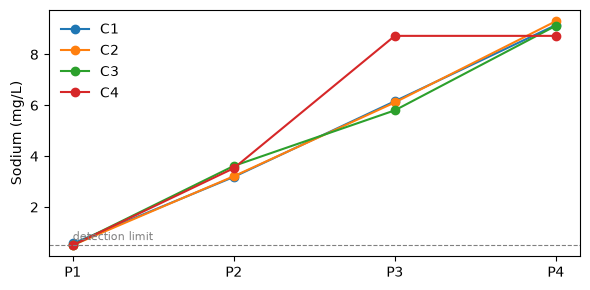

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
df["campaign"] = names[df["mixture_id"]].str[:2].values
for campaign, group in df.groupby("campaign"):
    group = group.sort_values("site")
    ax.plot(group["site"], group["value"], marker="o", label=campaign)
ax.axhline(lod, color="gray", ls="--", lw=0.8)
ax.text(0, lod + 0.2, "detection limit", color="gray", fontsize=8)
ax.set_ylabel("Sodium (mg/L)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [16]:
db.close()